# 생성과 출처 인용

**이 노트북에서 할 일**

1. 03절 After와 같은 두 가지 질문을 k=3으로 검색해, 문서 청크를 출처가 붙은 기록 모양으로 옮깁니다.
2. Ch 8 04절 코드로 메시지 목록을 만들어 답을 받고, 답의 출처 표시와 빠진 지킬 말을 검사합니다.
3. 메타데이터 `source` 값으로 출처를 만든 Before와, 쪽 번호가 든 출처로 보낸 After의 검사 결과를 비교합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 `labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.

인터넷 서비스에 요청을 모두 6번 보냅니다. 임베딩 모델 `text-embedding-3-small`에 2번, `gpt-5.4-mini`에 4번입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)에 적힌 100만 토큰당 0.02달러입니다.
mini 요금은 Ch 6 06절에서 확인한 값입니다.

**강의와 실습 범위** — 강의 시간에는 3~5절(기록으로 옮기기, 메시지 목록, 답과 출처 검사)을 설명합니다. 2절은 01·02절과 같은 코드라 강의에서 빠르게 확인합니다.
6절 기록 내용 대조, 7절 값 바꿔 보기와 Before·After는 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. pypdf 6.17.0, langchain 1.4.0, langchain-core 1.6.2입니다.
함께 쓰는 판은 langchain-openai 1.6.0, langchain-text-splitters 1.1.2입니다.
나머지는 openai 3.8.0과 python-dotenv 1.2.3입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch09-rag-first-run`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위 칸 넣기 전에는 초록 상자 k=3 검색 결과 page 2 1 3, 파란 상자 make_note doc_id와 page, 초록 상자 기록 3개 E01 p.2 p.1 p.3, 파란 상자 build_notes_messages 표시와 내용이 왼쪽에서 오른쪽으로 있고, 위 칸에서 아래 칸으로 메시지 3개 화살표가 내려오며, 아래 칸 받은 뒤에는 보라 상자 gpt-5.4-mini 입력 784토큰, 노란 상자 답 끝에 E01 p.2 E01 p.3, 노란 상자 check_answer 같은 기록 E01 p.2 p.3 빠진 지킬 말 없음이 왼쪽에서 오른쪽으로 있는 흐름도](attachment:04-1-검색에서-출처-검사까지.png)

위 칸은 답을 받기 전에 코드가 하는 일, 아래 칸은 답을 받은 뒤의 검사입니다.
초록 상자는 코드가 만든 자료, 파란 상자는 정의한 함수, 보라 상자는 모델, 노란 상자는 출력으로 확인할 값입니다.
노트북 3·4절이 위 칸, 5절이 아래 칸을 실행합니다.
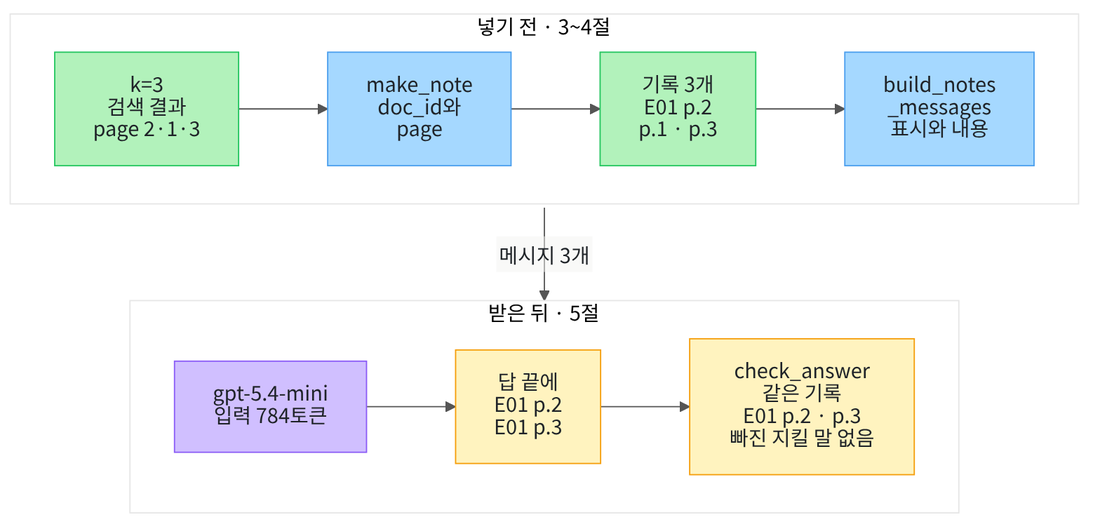

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01절과 같은 패키지를 씁니다. 이 노트북은 임베딩 모델과 답을 쓰는 모델을 모두 부릅니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.17.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langchain-text-splitters==1.1.2" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.17.0
langchain: 1.4.0


langchain-core: 1.6.2
langchain-openai: 1.6.0
langchain-text-splitters: 1.1.2
openai: 3.8.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `pypdf: 6.17.0`, `langchain: 1.4.0`, `openai: 3.8.0` 등 일곱 줄입니다.
준비물에 적은 기준 버전과 같습니다.

글 나누기, 임베딩, 벡터스토어, 모델 준비에 쓸 이름을 불러옵니다. 01절 준비 셀과 같은 이름입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 02절 `load_pdf_pages()`, Ch 8 03절 `find_missing_words()`, Ch 8 04절 `build_notes_messages()`·`check_answer()`를 가져옵니다.

도구 파일 판은 Ch 8 04절 판이 함수 바깥 이름에서 읽던 값을 인자로 받습니다. 함수 `build_notes_messages()`는 페르소나와 과업 명세를 앞의 두 인자로 받습니다.
함수 `check_answer()`는 지킬 말 목록을 셋째 인자로 받습니다.

In [2]:
# 문서 청크 나누기·임베딩·벡터스토어·모델 준비에 쓸 이름을 불러옵니다
import os

from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore
from langchain.chat_models import init_chat_model
# 02절과 Ch 8 03·04절 함수 네 개를 도구 파일에서 가져옵니다
from rag_tools import build_notes_messages, check_answer, find_missing_words, load_pdf_pages

01·03절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


01절과 같은 설정으로 답을 쓸 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.
실행마다 답 문장이 달라질 수 있습니다. Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정과 같은 것이 아닙니다.

## 2. 01~03절과 같은 문서 청크와 벡터스토어 만들기

이 노트북은 01~03절과 같은 E01 문서 청크 8개로 시작합니다. 경로를 고르는 셀은 01~03절과 같은 코드입니다.
실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [5]:
# 작업 폴더에서 본 E01.pdf 경로를 후보 세 개 가운데에서 고릅니다
candidates = [
    "labs/data/rag-corpus/pdf/easy/E01.pdf",
    "../../data/rag-corpus/pdf/easy/E01.pdf",
    "../../../data/rag-corpus/pdf/easy/E01.pdf",
]
pdf_path = None
for candidate in candidates:
    if os.path.exists(candidate):
        pdf_path = candidate
        break
print("PDF를 찾았는가:", pdf_path is not None)
print("고른 경로:", pdf_path)
assert pdf_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

PDF를 찾았는가: True
고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf


**결과 읽기** — 출력 줄은 `PDF를 찾았는가: True`와 `고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.
`notebooks` 폴더에서 열면 셋째 후보가 나옵니다.

준비 셀에서 가져온 02절 로더 함수 `load_pdf_pages()`는 PDF 경로와 문서 이름을 받아, 쪽마다 Document를 담은 목록을 반환합니다.
메타데이터에는 문서 이름 `doc_id`, 쪽 번호 `page`, 파일 이름 `source` 세 키를 적습니다.

로더 함수로 다섯 쪽을 읽고, 01~03절과 같은 크기 500자·겹침 50자로 나눕니다.
그다음 03절처럼 빈 벡터스토어를 만들어 문서 청크를 넣습니다. 임베딩 객체 이름은 01·03절과 같은 `embedding_model`입니다.
실행 전에 예상합니다. 03절처럼 문서 청크 8개가 모두 저장될 것입니다.

In [6]:
# E01.pdf를 문서 청크로 나누고, 03절과 같은 방법으로 벡터스토어에 넣습니다(임베딩 요청 1번)
pages = load_pdf_pages(pdf_path, "E01")
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents(pages)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
store = InMemoryVectorStore(embedding=embedding_model)
stored_ids = store.add_documents(chunks)
print("Document 수:", len(pages))
print("문서 청크 수:", len(chunks))
print("넣은 뒤 저장 항목 수:", len(store.store))

Document 수: 5
문서 청크 수: 8
넣은 뒤 저장 항목 수: 8


**결과 읽기** — 출력 줄은 `Document 수: 5`, `문서 청크 수: 8`, `넣은 뒤 저장 항목 수: 8`입니다. 01~03절과 같은 수입니다.

## 3. 두 가지를 묻는 질문을 검색해 기록 모양으로 옮기기

질문은 03절 Before·After와 같은 글입니다. 정기 휴관일과 대출 권수를 함께 묻고, 지킬 말도 03절과 같은 「월요일」과 「7권」입니다.
개수 k는 03절 After와 같은 3입니다. 03절에서 이 개수일 때 근거 글에 두 지킬 말이 모두 들어왔습니다.

메서드 `similarity_search()`는 01절에서 쓴 대로 가까운 문서 청크 k개를 반환합니다. 점수는 03절에서 봤으니 이번에는 메타데이터와 글자 수만 출력합니다.
실행 전에 예상합니다. 03절 After처럼 2쪽, 표지, 3쪽 순서일 것입니다.

In [7]:
# 03절 After와 같은 질문을 k=3으로 검색하고, 문서 청크마다 메타데이터와 글자 수를 봅니다(임베딩 요청 1번)
combined_question = "미르시립도서관의 정기 휴관일은 언제이고, 도서는 몇 권까지 빌릴 수 있나요?"
combined_keep_words = ["월요일", "7권"]
hits = store.similarity_search(combined_question, k=3)
print("검색 결과 수:", len(hits))
print("k=3 검색 결과(메타데이터 | 글자 수):")
for hit in hits:
    print(hit.metadata, "|", len(hit.page_content))
assert len(hits) == 3

검색 결과 수: 3
k=3 검색 결과(메타데이터 | 글자 수):
{'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'} | 498
{'doc_id': 'E01', 'page': 1, 'source': 'E01.pdf'} | 45
{'doc_id': 'E01', 'page': 3, 'source': 'E01.pdf'} | 498


**결과 읽기** — 라벨 줄 아래 세 줄이 가까운 순서입니다. 첫 줄은 `{'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'} | 498`입니다.
둘째 줄은 `'page': 1`인 표지 `45`자, 셋째 줄은 `'page': 3`인 `498`자입니다. `assert`도 통과했습니다.

순서는 03절 After와 같은 2쪽, 표지, 3쪽입니다. 메타데이터 세 키 가운데 줄마다 값이 다른 것은 쪽 번호 `page`뿐입니다.
키 `doc_id`와 `source`는 세 줄 모두 같습니다.

검색 결과를 Ch 8 04절 함수가 읽는 모양으로 옮깁니다. Ch 8 04절 함수는 기록 딕셔너리에서 키 `출처`와 `내용`을 읽었고, 출처는 `E01 p.2` 모양이었습니다.

함수 `make_note()`는 문서 청크 하나를 받아, 메타데이터의 문서 이름과 쪽 번호로 출처를 만듭니다. 내용에는 본문을 그대로 넣습니다.
출처 글은 01절처럼 변수만 넣은 f-string으로 만듭니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [8]:
# 문서 청크 하나를 받아, 문서 이름과 쪽 번호로 만든 출처와 본문을 담은 기록을 반환하는 함수를 정의합니다
def make_note(chunk):
    doc_id = chunk.metadata["doc_id"]
    page = chunk.metadata["page"]
    note = {"출처": f"{doc_id} p.{page}", "내용": chunk.page_content}
    return note

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

검색한 문서 청크 3개를 검색 순서대로 기록 모양으로 옮기고, 출처만 모아 봅니다.
Ch 8에서는 사람이 원문을 읽고 한 문장씩 기록을 적었습니다. 이번 기록의 내용은 문서 청크 본문 그대로라서 훨씬 깁니다.
실행 전에 예상합니다. 출처 세 개가 모두 다른 쪽 번호일 것입니다.

In [9]:
# 검색한 문서 청크 3개를 검색 순서대로 기록으로 옮기고, 출처만 모아 봅니다
notes = []
note_sources = []
for hit in hits:
    note = make_note(hit)
    notes.append(note)
    note_sources.append(note["출처"])
print("기록 수:", len(notes))
print("기록의 출처:", note_sources)
print("첫 기록의 키:", notes[0].keys())

기록 수: 3
기록의 출처: ['E01 p.2', 'E01 p.1', 'E01 p.3']
첫 기록의 키: dict_keys(['출처', '내용'])


**결과 읽기** — 출력 줄은 `기록 수: 3`과 `기록의 출처: ['E01 p.2', 'E01 p.1', 'E01 p.3']`입니다.
마지막 줄은 `첫 기록의 키: dict_keys(['출처', '내용'])`입니다.

세 출처는 쪽 번호가 모두 다릅니다. 이 출처에 대괄호를 붙인 `[E01 p.2]`가 Ch 8과 01절의 출처 표시 모양입니다.

## 4. 기록 목록으로 메시지 목록 만들기

메시지 목록은 01절과 같은 모양입니다. system에는 페르소나, developer에는 과업 명세, user에는 근거와 질문을 넣습니다.
페르소나와 과업 명세는 01절과 같은 글입니다. 과업 명세는 문장마다 끝에 근거 앞에 붙은 출처 표시를 그대로 적게 합니다.

In [10]:
# system에 넣을 페르소나와 developer에 넣을 과업 명세를 01절과 같은 글로 만듭니다
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 근거 앞에 붙은 출처 표시를 그대로 적으세요."
print("페르소나:", persona_text)
print("과업 명세:", task_text)

페르소나: 당신은 미르시립도서관 안내 담당자입니다.
과업 명세: 주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 근거 앞에 붙은 출처 표시를 그대로 적으세요.


**결과 읽기** — 두 줄은 `페르소나:`와 `과업 명세:`로 시작합니다. 01절 7절 출력과 같은 글입니다.

메시지 목록은 준비 셀에서 가져온 Ch 8 04절 `build_notes_messages()`로 만듭니다. 기록마다 대괄호 출처 표시, 빈칸, 내용, 줄바꿈을 이어 근거 글을 만듭니다.
그 뒤에 빈 줄과 `질문: `, 질문을 붙여 user 글로 삼습니다. 페르소나와 과업 명세는 앞의 두 인자로 넘깁니다.
출처 표시 `[E01 p.2]`는 이 함수가 기록의 출처에 대괄호를 붙여 만듭니다.

기록 3개와 두 가지 질문으로 메시지 목록을 만듭니다. 목록의 셋째 메시지에서 둘째 값이 user 글이므로 `messages[2][1]`로 꺼냅니다.
Ch 8 07절에서 목록의 user 글을 꺼낸 모양과 같습니다. user 글은 여러 줄이라 라벨 줄을 따로 출력합니다.

실행 전에 예상합니다. 출처 표시가 붙은 줄이 세 번 나오고, 맨 끝 줄은 질문일 것입니다.

In [11]:
# 기록 3개와 두 가지 질문으로 메시지 목록을 만들고, user 글을 봅니다
messages = build_notes_messages(persona_text, task_text, notes, combined_question)
user_text = messages[2][1]
print("메시지 수:", len(messages))
print("user 글:")
print(user_text)

메시지 수: 3
user 글:
[E01 p.2] 1. 도서관 소개
미르시립도서관은 1998년 10월 미르시 중앙동에 문을 연 공공도서관입니다. 지상 4층, 지하 1층 규모
이며 장서 42만 권과 전자책 6만 종을 보유하고 있습니다. 2024년 리모델링을 마치고 3층에 '메이커 스
페이스'와 '조용한 열람실'을 새로 열었습니다.
도서관의 사명은 "누구나, 언제나, 무료로"입니다. 시민 모두가 자료를 자유롭게 이용하고 배울 수 있도
록 돕는 것을 최우선으로 합니다.
2. 이용 시간
평일(화~금) 이용 시간은 오전 9시부터 오후 10시까지입니다. 토요일과 일요일은 오전 9시부터 오후 6
시까지 문을 엽니다.
매주 월요일은 정기 휴관일 입니다. 법정 공휴일에도 휴관하며, 공휴일이 월요일과 겹치면 그 다음 날인
화요일에도 휴관합니다.
어린이자료실(1층)은 요일과 관계없이 오후 6시에 문을 닫습니다. 디지털자료실(2층)은 오후 9시까지
이용할 수 있습니다.
구역 평일 주말 비고
종합자료실(2층) 09:00~22:00 09:00~18:00
[E01 p.1] 미르시립도서관 이용 안내
미르시립도서관
2026년판
발행 2026. 3. 1.
1
[E01 p.3] 모바일 회원증은 '미르시 도서관' 앱에서 발급받을 수 있으며, 플라스틱 회원증과 동일하게 사용할 수 있
습니다.
4. 자료 대출
회원 한 사람이 한 번에 빌릴 수 있는 자료는 도서 7권과 영상 자료 2점 입니다. 대출 기간은 도서 14일,
영상 자료 7일입니다.
대출 기간은 다른 이용자의 예약이 없는 경우 1회에 한해 7일 연장 할 수 있습니다. 연장은 반납 예정일
전에 앱, 홈페이지, 전화(032-000-1998)로 신청합니다.
정기간행물 최신호, 참고도서(사전·연감), 향토자료는 관내에서만 열람할 수 있고 대출되지 않습니다.
5. 반납과 연체
반납은 이용 시간 중 각 자료실 데스크에서 하거나, 정문 오른쪽의 무인반납함을 24시간 이용할 수 있습
니다. 무인반납함으로 반납한 자료는 다음 개관일 오전에 처리됩니다.
반납 

**결과 읽기** — 첫 줄은 `메시지 수: 3`입니다. 라벨 줄 `user 글:` 아래 첫 줄은 `[E01 p.2] 1. 도서관 소개`입니다.
2쪽 근거 가운데 `매주 월요일은 정기 휴관일 입니다.`로 시작하는 줄이 있습니다.
그 뒤 `[E01 p.1] 미르시립도서관 이용 안내` 줄에서 표지 근거가 시작하고, 이어서 `[E01 p.3]`으로 시작하는 줄이 3쪽 근거를 엽니다.
3쪽 근거에는 `도서 7권과 영상 자료 2점 입니다.`가 든 줄이 있고, 맨 끝 줄은 `질문:`으로 시작합니다.

출처 표시는 기록마다 한 번, 근거 첫 줄 앞에만 붙습니다. 근거 본문은 PDF에서 읽은 글이라 줄이 PDF 줄 끝에서 바뀝니다.
Ch 8에서는 사람이 한 문장씩 적은 기록이 들어갔고, 이번에는 검색이 고른 문서 청크 본문 세 개가 들어갔습니다.

## 5. 답 받고 출처 인용 검사하기

메시지 목록을 1절의 모델로 보냅니다. 응답의 속성 `text`는 답 글이고, `usage_metadata["input_tokens"]`는 실제 입력 토큰 수입니다. 둘 다 Ch 6 01절에서 배웠습니다.
답은 여러 줄일 수 있어 라벨 줄 `답:`을 따로 출력합니다.

실행 전에 예상합니다. 휴관 문장 끝에는 `[E01 p.2]`, 대출 권수 문장 끝에는 `[E01 p.3]`이 붙을 것입니다.

In [12]:
# 기록 3개를 넣은 메시지 목록을 모델로 보내고, 답과 실제 입력 토큰 수를 봅니다(요청 1번)
response = model.invoke(messages)
answer_text = response.text
input_tokens = response.usage_metadata["input_tokens"]
print("답:")
print(answer_text)
print("실제 입력 토큰 수:", input_tokens)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 도서는 한 번에 7권까지 빌릴 수 있습니다. [E01 p.2] [E01 p.3]
실제 입력 토큰 수: 784


**결과 읽기** — 라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`로 시작합니다.
둘째 문장은 `도서는 한 번에 7권까지 빌릴 수 있습니다.`이고, 그 뒤에 `[E01 p.2] [E01 p.3]` 두 표시가 나란히 붙었습니다.
마지막 줄은 `실제 입력 토큰 수: 784`입니다.

과업 명세는 문장마다 끝에 출처를 적으라고 했지만, 이번 답은 두 표시를 답 끝에 모아 적었습니다.
표지 표시 `[E01 p.1]`은 답에 없습니다.
입력 784토큰에는 기록 세 개의 본문이 들어 있습니다. Ch 8 01절 입력 가용분 440보다 크고, 이 노트북은 입력 가용분을 따로 정하지 않았습니다.

답에 붙은 출처 표시가 넣은 기록의 출처인지 검사합니다. 답이 근거에 적힌 출처를 가리키는 것을 출처 인용(citation)이라고 부릅니다.
보고서 끝에 「자료: 안내 책자 3쪽」을 적어 읽는 사람이 그 쪽을 펴 보게 하는 것과 비슷합니다.

검사에는 준비 셀에서 가져온 Ch 8 04절 `check_answer()`를 씁니다. 함수 안에서는 Ch 8 02절 `find_cited_notes()`가 답 글에 출처 표시가 든 기록을 모읍니다.
Ch 8 03절 `find_missing_words()`는 답에 없는 지킬 말을 모읍니다. 지킬 말 목록은 셋째 인자로 받으므로 3절의 `combined_keep_words`를 넘깁니다.

반환값은 키 두 개인 딕셔너리입니다. 답의 출처 표시와 같은 기록의 출처 목록, 답에서 빠진 지킬 말 목록입니다.

5절 답을 검사합니다. 이 검사는 Ch 8 04절처럼 말과 표시가 있는지만 봅니다. 답의 품질 점수가 아닙니다.
실행 전에 예상합니다. 표지 `E01 p.1`은 답에 쓰이지 않을 것입니다.

In [13]:
# 5절 답의 출처 표시와 같은 기록, 답에서 빠진 지킬 말을 검사합니다
check = check_answer(answer_text, notes, combined_keep_words)
print("답 검사:", check)

답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2', 'E01 p.3'], '답에서 빠진 지킬 말': []}


**결과 읽기** — 출력 줄은 `답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2', 'E01 p.3'], '답에서 빠진 지킬 말': []}`입니다.

답의 표시는 넣은 기록 가운데 2쪽과 3쪽 기록의 출처와 같았고, 두 지킬 말도 답에 모두 있었습니다.
이 결과는 표시와 말이 답 어딘가에 있다는 뜻입니다. 휴관 문장과 대출 권수 문장이 각각 어느 기록에서 왔는지는 이 검사로 알 수 없습니다.

## 6. 기록 내용과 대조하기

검사 함수는 출처 표시가 답 어딘가에 있는지만 봅니다. 그 표시가 붙은 문장이 정말 그 기록에서 온 것인지는 보지 않습니다.
그래서 Ch 7 05절 근거 대조처럼, 기록마다 무엇이 적혀 있는지 원문 쪽에서 확인합니다.

준비 셀에서 가져온 `find_missing_words()`로 기록 내용마다 빠진 지킬 말을 봅니다. 실행 전에 예상합니다. 「월요일」은 2쪽, 「7권」은 3쪽 기록에만 있을 것입니다.

In [14]:
# 기록마다 내용에서 빠진 지킬 말을 봐서, 어느 기록에 어느 지킬 말이 있는지 확인합니다
print("기록마다 내용에서 빠진 지킬 말(출처 | 빠진 지킬 말):")
for note in notes:
    note_missing = find_missing_words(note["내용"], combined_keep_words)
    print(note["출처"], "|", note_missing)

기록마다 내용에서 빠진 지킬 말(출처 | 빠진 지킬 말):
E01 p.2 | ['7권']
E01 p.1 | ['월요일', '7권']
E01 p.3 | ['월요일']


**결과 읽기** — 라벨 줄 아래 세 줄은 `E01 p.2 | ['7권']`, `E01 p.1 | ['월요일', '7권']`, `E01 p.3 | ['월요일']`입니다.

「월요일」은 2쪽 기록에만, 「7권」은 3쪽 기록에만 있습니다. 표지 기록에는 두 말이 모두 없습니다.
그래서 이번 답의 휴관 문장은 2쪽 기록과, 대출 권수 문장은 3쪽 기록과 대조합니다.
이번 답은 두 표시를 끝에 모아 적어서, 문장과 기록의 짝은 사람이 기록 내용을 보고 맞췄습니다.

지킬 말이 기록에 있어도 답 문장의 뜻까지 맞다는 보장은 없습니다. 뜻은 원문을 읽고 확인합니다.

## 7. 값 바꿔 보기 — 과업 명세에서 출처 문장 빼기

바꾸는 값은 developer에 넣는 과업 명세 하나입니다. 「문장마다 끝에 … 출처 표시를 그대로 적으세요」를 빼고 앞 두 지시만 남깁니다.
페르소나, user 글, 모델은 5절과 같습니다. 그래서 `build_notes_messages()` 대신 목록을 직접 적습니다.

실행 전에 예상합니다. 근거 앞에 출처 표시가 있어도, 지시가 없으면 답에 출처 표시를 적지 않을 수 있습니다.

In [15]:
# 과업 명세에서 출처 문장만 뺀 목록을 같은 모델로 보내고, 답과 검사 결과를 봅니다(요청 1번)
plain_task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하세요."
plain_messages = [
    ("system", persona_text),
    ("developer", plain_task_text),
    ("user", user_text),
]
plain_response = model.invoke(plain_messages)
plain_text = plain_response.text
plain_check = check_answer(plain_text, notes, combined_keep_words)
print("답:")
print(plain_text)
print("답 검사:", plain_check)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 도서는 한 번에 7권까지 빌릴 수 있습니다.
답 검사: {'답의 출처 표시와 같은 기록': [], '답에서 빠진 지킬 말': []}


**결과 읽기** — 라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`로 시작하고, 출처 표시가 없습니다.
마지막 줄은 `답 검사: {'답의 출처 표시와 같은 기록': [], '답에서 빠진 지킬 말': []}`입니다.

이번 실행에서는 근거 앞에 출처 표시가 있어도, 과업 명세에 출처 문장이 없자 답에 표시를 적지 않았습니다.
두 지킬 말은 5절 답처럼 모두 있었습니다. 말만 검사해서는 이 답을 원문의 어느 쪽과 대조할지 알 수 없습니다.
한 번 본 결과라, 출처 문장이 없으면 늘 표시를 빼는지는 이 실행으로 말하지 않습니다.

## Before — 메타데이터 `source` 값으로 출처 만들기

3절 메타데이터에는 키 `source`도 있습니다. 영어 source는 「출처」라는 뜻이라, 기록의 `출처`에 이 값을 넣고 싶어집니다.
Before 코드는 `make_note()` 대신 `hit.metadata["source"]`를 출처로 넣습니다. 페르소나, 과업 명세, 질문, 모델은 5절과 같습니다.

실행 전에 예상합니다. 세 기록의 출처가 모두 같은 글이 될 것입니다.

In [16]:
# 메타데이터 source 값을 출처로 넣은 기록 3개와 메시지 목록을 만듭니다
before_notes = []
before_sources = []
for hit in hits:
    before_note = {"출처": hit.metadata["source"], "내용": hit.page_content}
    before_notes.append(before_note)
    before_sources.append(before_note["출처"])
before_messages = build_notes_messages(persona_text, task_text, before_notes, combined_question)
print("기록의 출처:", before_sources)

기록의 출처: ['E01.pdf', 'E01.pdf', 'E01.pdf']


**결과 읽기** — 출력 줄은 `기록의 출처: ['E01.pdf', 'E01.pdf', 'E01.pdf']`입니다.

세 기록의 출처가 모두 같은 파일 이름입니다. 로더 함수가 쪽마다 메타데이터 `source`에 같은 파일 이름을 적었기 때문입니다.
그래서 user 글의 세 근거 앞에도 같은 표시 `[E01.pdf]`가 붙습니다. 이 셀은 요청을 보내지 않아서, 실행할 때마다 같은 결과가 나옵니다.

이 목록을 같은 모델로 보냅니다.

In [17]:
# source 값을 출처로 넣은 메시지 목록을 같은 모델로 보냅니다(요청 1번)
before_response = model.invoke(before_messages)
before_text = before_response.text
print("답:")
print(before_text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. [E01.pdf]  
도서는 한 번에 7권까지 빌릴 수 있습니다. [E01.pdf]


**결과 읽기** — 라벨 줄 아래 답은 두 줄입니다. 첫 줄은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다. [E01.pdf]`입니다.
둘째 줄은 `도서는 한 번에 7권까지 빌릴 수 있습니다. [E01.pdf]`입니다.

문장마다 끝에 `[E01.pdf]`가 붙었습니다. 답은 과업 명세대로 근거 앞의 표시를 옮겨 적었습니다. 그러나 이 표시로는 PDF의 몇 쪽을 펴 봐야 할지 알 수 없습니다.

같은 검사 함수로 Before 답을 봅니다. 기록 목록은 Before 기록 `before_notes`를 넣습니다.

In [18]:
# Before 답의 출처 표시와 같은 기록, 답에서 빠진 지킬 말을 검사합니다
before_check = check_answer(before_text, before_notes, combined_keep_words)
print("답 검사:", before_check)

답 검사: {'답의 출처 표시와 같은 기록': ['E01.pdf', 'E01.pdf', 'E01.pdf'], '답에서 빠진 지킬 말': []}


**결과 읽기** — 출력 줄은 `답 검사: {'답의 출처 표시와 같은 기록': ['E01.pdf', 'E01.pdf', 'E01.pdf'], '답에서 빠진 지킬 말': []}`입니다.

검사 함수는 기록마다 대괄호 표시가 답에 있는지 봅니다. 세 기록의 표시가 모두 `[E01.pdf]`라서, 답에 나온 표시가 세 기록 모두에 맞았습니다.
휴관도 대출 권수도 적혀 있지 않은 표지 기록까지 목록에 들어갔습니다.
빠진 지킬 말은 빈 목록이라, 말 검사만으로는 이 결함이 보이지 않습니다.

## After — 쪽 번호가 든 출처로 다시 보내기

고치는 곳은 기록의 출처를 만드는 코드입니다. 3절 `make_note()`처럼 `doc_id`와 `page`로 `E01 p.2` 모양의 출처를 만듭니다.
페르소나, 과업 명세, 질문, 모델은 Before와 같습니다. 4절에서 만든 메시지 목록 `messages`를 다시 보냅니다.

실행 전에 예상합니다. 5절처럼 쪽 번호가 다른 출처 표시가 답에 붙을 것입니다.

In [19]:
# 쪽 번호가 든 출처로 만든 4절 메시지 목록을 같은 모델로 다시 보냅니다(요청 1번)
after_response = model.invoke(messages)
after_text = after_response.text
print("답:")
print(after_text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 도서는 한 번에 7권까지 빌릴 수 있습니다. [E01 p.2] [E01 p.3]


**결과 읽기** — 라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`로 시작합니다.
둘째 문장은 `도서는 한 번에 7권까지 빌릴 수 있습니다.`이고, 끝에 `[E01 p.2] [E01 p.3]`이 붙었습니다.

이번 실행에서는 5절 답과 같은 글이었습니다. 같은 목록을 temperature 0으로 보내도 늘 같은 답이 온다고 보장하지 않습니다.

같은 검사 함수로 After 답을 봅니다. 기록 목록은 3절 `notes`입니다.

In [20]:
# After 답의 출처 표시와 같은 기록, 답에서 빠진 지킬 말을 검사합니다
after_check = check_answer(after_text, notes, combined_keep_words)
print("Before 기록의 출처:", before_sources)
print("After 기록의 출처:", note_sources)
print("답 검사:", after_check)

Before 기록의 출처: ['E01.pdf', 'E01.pdf', 'E01.pdf']
After 기록의 출처: ['E01 p.2', 'E01 p.1', 'E01 p.3']
답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2', 'E01 p.3'], '답에서 빠진 지킬 말': []}


**결과 읽기** — 첫 줄은 `Before 기록의 출처: ['E01.pdf', 'E01.pdf', 'E01.pdf']`입니다.
둘째 줄은 `After 기록의 출처: ['E01 p.2', 'E01 p.1', 'E01 p.3']`입니다.
마지막 줄은 `답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2', 'E01 p.3'], '답에서 빠진 지킬 말': []}`입니다.

두 답 모두 빠진 지킬 말이 없었습니다. 달라진 것은 답의 출처 표시로 기록을 가려낼 수 있는가입니다.
Before 답에서는 세 기록이 모두 맞았고, After 답에서는 2쪽과 3쪽 기록만 맞았습니다.
출처가 쪽마다 달라야 6절처럼 답 문장을 기록 내용과 대조할 수 있습니다. 이 비교는 질문 하나를 조건마다 한 번 보낸 결과입니다.

## 정리

- 검색한 문서 청크 3개를 기록으로 옮겼습니다. 출처는 메타데이터의 문서 이름과 쪽 번호로 만들었습니다.
- Ch 8 04절 함수로 메시지 목록을 만들어 답을 받았습니다. 답의 `[E01 p.2] [E01 p.3]`은 넣은 두 기록의 출처와 같았습니다.
- 파일 이름 `source`로 출처를 만든 Before에서는 세 기록이 모두 검사에 맞았습니다. 쪽 번호가 든 After에서는 두 기록만 맞았습니다.

다음 05절에서는 답만 읽지 않고 검색한 문서 청크의 출처를 함께 보며, 첫 실패를 일부러 만들어 봅니다.